# 06 · Validação experimental dos modelos

**Ementa 06** · Uma AUC de 0,98 no teste diz pouco sobre o que acontecerá quando o retinógrafo do projeto fotografar o primeiro paciente.
Validar um modelo de triagem é responder, com números e incertezas: **quantos doentes ele deixa passar? Quantos saudáveis encaminha?
Isso se mantém numa câmera nova? Quando ele erra, por quê?**

Avaliamos aqui **os modelos que vão para o dispositivo** — os `.tflite` int8 de `modelos/`, rodando no LiteRT — e não os modelos Keras.
Você vai: **(1)** entender a escolha do limiar de triagem; **(2)** medir sensibilidade e especificidade com IC no teste interno e nas bases
**externas**; **(3)** investigar a queda de desempenho (grau da RD, definição do rótulo, câmera); **(4)** ver o efeito de recalibrar o limiar na
câmera nova; **(5)** checar a calibração das probabilidades e o VPP na população real; **(6)** testar o controle de qualidade do Módulo 02 como
"porteiro"; **(7)** olhar os erros com Grad-CAM; **(8)** escrever o **cartão do modelo**.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import json
from datetime import date
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from retina_iae import dados as D, metricas as Me, visualizacao as V
from retina_iae.inferencia import ModeloTFLite

V.configurar_estilo()
cache = D.Cache()
man = D.carregar_manifesto().set_index("id")
cfg = json.loads((D.MODELOS / "config_triagem.json").read_text(encoding="utf-8"))
modelos = {t: ModeloTFLite(D.MODELOS / m["arquivo"], threads=4) for t, m in cfg["modelos"].items()}
limiares = {t: m["limiar"] for t, m in cfg["modelos"].items()}
pd.DataFrame({t: {"arquivo": m["arquivo"], "arquitetura": m["arquitetura"], "limiar": m["limiar"]} for t, m in cfg["modelos"].items()}).T

,arquivo,arquitetura,limiar
rd,rd_efficientnet_lite0_int8.tflite,efficientnet_lite0,0.7812
glaucoma,glaucoma_efficientnet_lite0_int8.tflite,efficientnet_lite0,0.332
dmri,dmri_efficientnet_lite0_int8.tflite,efficientnet_lite0,0.0938


Predições de cada modelo em **todas** as imagens da sua tarefa (validação, teste e externas) — ≈ 10 mil inferências int8:

In [2]:
pred = []
for tarefa, mod in modelos.items():
    p = D.carregar_particoes(tarefa)
    p = p[p.particao != "treino"].reset_index(drop=True)
    p["prob"] = mod.prever(cache[p.id])
    pred.append(p)
pred = pd.concat(pred, ignore_index=True)
pred["grupo"] = pred.paciente.where(pred.paciente != "", pred.id)
pred.to_csv(D.SAIDAS / "predicoes_tflite.csv", index=False)
pred.groupby(["tarefa", "particao", "fonte"]).size().unstack().fillna(0).astype(int)

fonte               APTOS  DDR  G1020  ODIR  RFMiD
tarefa   particao                                 
dmri     externo        0    0      0     0    207
         teste          0    0      0   468      0
         validacao      0    0      0   475      0
glaucoma externo        0    0   1020     0      0
         teste          0    0      0   484      0
         validacao      0    0      0   484      0
rd       externo        0  500      0  4481      0
         teste        550    0      0     0      0
         validacao    549    0      0     0      0

## 1. O limiar: uma decisão clínica, tomada na validação

O modelo devolve um escore entre 0 e 1. "Encaminhar" significa escore ≥ limiar. Subir o limiar troca sensibilidade por especificidade.
Num programa de **triagem**, deixar passar um doente (falso negativo) costuma custar mais do que encaminhar um saudável (falso positivo) —
por isso o notebook 04 escolheu, **na validação**, o maior limiar com **sensibilidade ≥ 90 %**. Como seria com outros alvos:

In [3]:
linhas = []
for tarefa in modelos:
    v = pred[(pred.tarefa == tarefa) & (pred.particao == "validacao")]
    for alvo in (0.80, 0.85, 0.90, 0.95):
        lim = Me.limiar_para_sensibilidade(v.alvo, v.prob, alvo)
        m = Me.metricas_no_limiar(v.alvo, v.prob, lim)
        linhas.append({"tarefa": tarefa, "sensibilidade alvo": f"{alvo:.0%}", "limiar": lim, "sensibilidade": m["sensibilidade"],
                       "especificidade": m["especificidade"], "encaminhados": m["encaminhados"]})
pd.DataFrame(linhas).set_index(["tarefa", "sensibilidade alvo"]).round(3)

limiar  sensibilidade  especificidade  \
tarefa   sensibilidade alvo                                          
rd       80%                  0.910          0.807           0.975   
         85%                  0.840          0.852           0.963   
         90%                  0.781          0.901           0.960   
         95%                  0.723          0.951           0.951   
glaucoma 80%                  0.656          0.829           0.880   
         85%                  0.531          0.854           0.804   
         90%                  0.332          0.902           0.693   
         95%                  0.230          0.951           0.603   
dmri     80%                  0.371          0.810           0.926   
         85%                  0.250          0.857           0.903   
         90%                  0.094          0.905           0.801   
         95%                  0.016          0.952           0.460   

                             encaminhados  
tarefa   sensibilidade alvo                
rd       80%                        0.342  
         85%                        0.368  
         90%                        0.390  
         95%                        0.415  
glaucoma 80%                        0.180  
         85%                        0.252  
         90%                        0.357  
         95%                        0.444  
dmri     80%                        0.139  
         85%                        0.164  
         90%                        0.261  
         95%                        0.577

Com poucos positivos na validação (42 DMRI, 41 glaucomas), cada caso vale 2–2,5 pontos de sensibilidade: o limiar é **instável**, e a sensibilidade
realizada em dados novos vai oscilar em torno do alvo. Por isso o limiar é reportado **junto** com os intervalos de confiança do teste.

## 2. Teste interno × validação externa

O mesmo limiar, **sem nenhum ajuste**, aplicado ao teste (mesma fonte) e às bases externas. IC 95 %: AUC por *bootstrap* reamostrando **pacientes**;
sensibilidade e especificidade por Wilson.

In [4]:
linhas = []
for tarefa in modelos:
    sub = pred[(pred.tarefa == tarefa) & (pred.particao.isin(["teste", "externo"]))]
    for (particao, fonte), g in sub.groupby(["particao", "fonte"]):
        r = Me.relatorio(g.alvo, g.prob, limiares[tarefa], grupos=g.grupo.to_numpy(), n_boot=1000)
        linhas.append({"tarefa": tarefa, "conjunto": f"{particao} · {fonte}", **r})
desempenho = pd.DataFrame(linhas).set_index(["tarefa", "conjunto"])
cols = ["n", "positivos", "AUC", "AUC_IC", "sensibilidade", "sens_IC", "especificidade", "esp_IC", "VPP", "encaminhados"]
desempenho[cols].round(3)

n  positivos    AUC       AUC_IC  sensibilidade  \
tarefa   conjunto                                                              
rd       externo · DDR     500        240  0.933  0.910–0.955          0.671   
         externo · ODIR   4481       1608  0.675  0.655–0.696          0.244   
         teste · APTOS     550        223  0.986  0.978–0.993          0.888   
glaucoma externo · G1020  1020        296  0.541  0.499–0.580          0.365   
         teste · ODIR      484         42  0.911  0.861–0.953          0.952   
dmri     externo · RFMiD   207         69  0.978  0.948–0.998          0.928   
         teste · ODIR      468         41  0.897  0.826–0.957          0.756   

                            sens_IC  especificidade     esp_IC    VPP  \
tarefa   conjunto                                                       
rd       externo · DDR    0.61–0.73           0.985  0.96–0.99  0.976   
         externo · ODIR   0.22–0.27           0.968  0.96–0.97  0.810   
         teste · APTOS    0.84–0.92           0.957  0.93–0.97  0.934   
glaucoma externo · G1020  0.31–0.42           0.704  0.67–0.74  0.335   
         teste · ODIR     0.84–0.99           0.672  0.63–0.71  0.216   
dmri     externo · RFMiD  0.84–0.97           0.971  0.93–0.99  0.941   
         teste · ODIR     0.61–0.86           0.852  0.82–0.88  0.330   

                          encaminhados  
tarefa   conjunto                       
rd       externo · DDR           0.330  
         externo · ODIR          0.108  
         teste · APTOS           0.385  
glaucoma externo · G1020         0.316  
         teste · ODIR            0.382  
dmri     externo · RFMiD         0.329  
         teste · ODIR            0.201

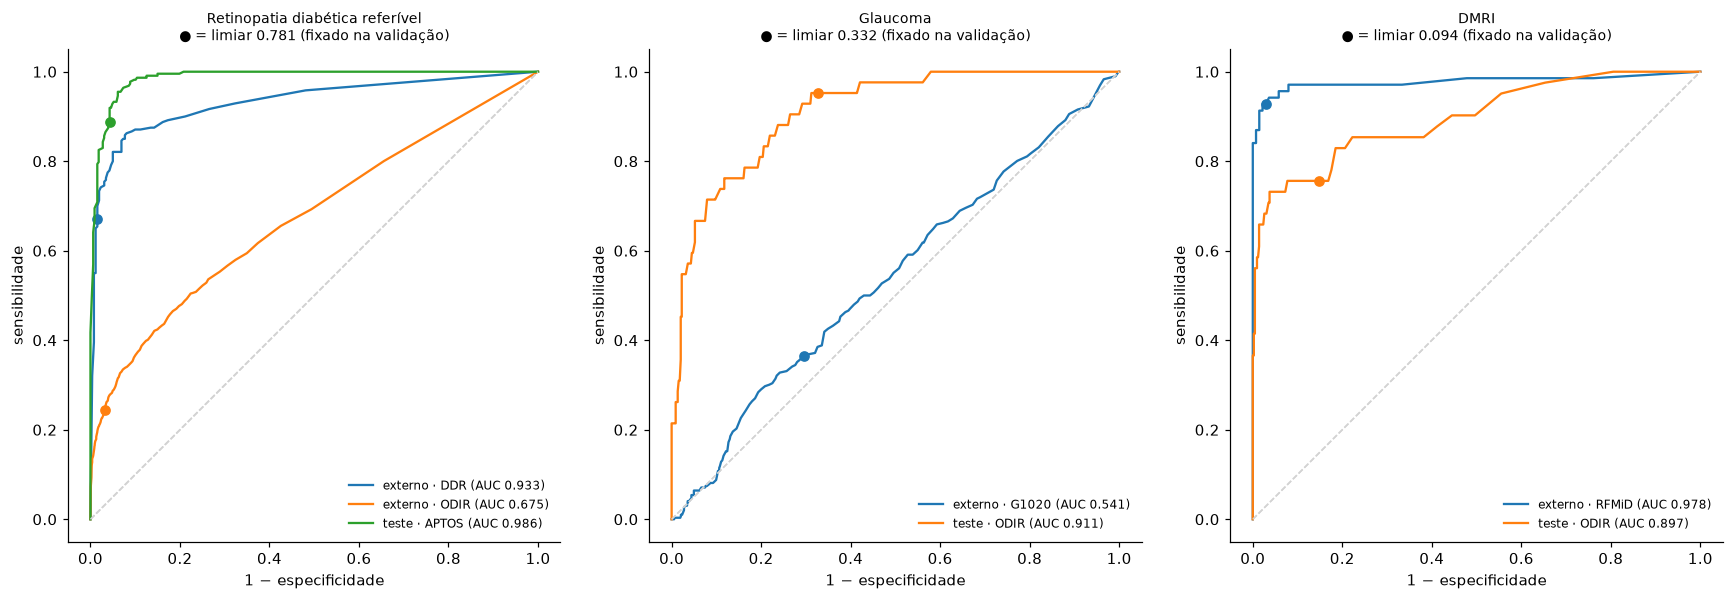

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, tarefa in zip(axs, modelos):
    sub = pred[(pred.tarefa == tarefa) & (pred.particao.isin(["teste", "externo"]))]
    for (particao, fonte), g in sub.groupby(["particao", "fonte"]):
        m = Me.metricas_no_limiar(g.alvo, g.prob, limiares[tarefa])
        V.curva_roc(g.alvo, g.prob, ax, f"{particao} · {fonte} (AUC {Me.auc(g.alvo, g.prob):.3f})",
                    ponto=(m["sensibilidade"], m["especificidade"]))
    ax.set_title(f"{cfg['modelos'][tarefa]['nome']}\n● = limiar {limiares[tarefa]:.3f} (fixado na validação)", fontsize=9)
fig.tight_layout(); V.salvar_figura(fig, "06_roc_interno_externo"); plt.show()

Cada tarefa conta uma história diferente (números exatos na tabela):

* **RD.** No teste do APTOS: AUC ≈ 0,99, sensibilidade ≈ 0,89. No **DDR** a AUC continua alta (≈ 0,93) — o modelo ainda **ordena** bem —, mas
  no mesmo limiar a sensibilidade cai para ≈ 0,67: os escores do DDR ficam, em geral, mais baixos. É um problema de **escala**, e a seção 4 mostra que tem conserto.
  No **ODIR** a AUC cai para ≈ 0,68 e a sensibilidade para ≈ 0,24 — aqui o problema é outro (seção 3).
* **Glaucoma.** No teste do ODIR, AUC ≈ 0,91 e sensibilidade ≈ 0,95, com especificidade baixa (≈ 0,67): um terço dos saudáveis seria encaminhado.
  No **G1020**, AUC ≈ 0,54, com IC que inclui 0,5: **o modelo não generaliza** para essa base. Os rótulos do G1020 vêm do exame clínico completo,
  e nem um modelo treinado dentro do próprio G1020 passa do acaso (notebook 00). Ou o sinal não está na foto, ou não está na resolução de 224 px.
* **DMRI.** O externo (RFMiD, AUC ≈ 0,98) saiu **melhor** que o teste interno (ODIR, ≈ 0,90). Validação externa não é sempre "pior": depende do
  **caso a caso** de cada base — as DMRI do RFMiD tendem a ser casos mais avançados e mais visíveis. Com 69 positivos, o IC é largo.

Moral: **um único número de teste interno não descreve um modelo**. A pergunta "funciona?" só tem resposta para uma população e uma câmera.

## 3. Por que cai? Dissecando a RD por grau

O DDR informa o **grau** de cada imagem. Para cada grau, a fração encaminhada pelo modelo de RD (para graus 2–4 é a sensibilidade; para 0–1, a taxa de
falsos positivos):

In [6]:
dd = pred[(pred.tarefa == "rd") & (pred.fonte == "DDR")].copy()
dd["grau"] = man.loc[dd.id, "grau"].astype(int).to_numpy()
dd["encaminhado"] = dd.prob >= limiares["rd"]
ap = pred[(pred.tarefa == "rd") & (pred.particao == "teste")].copy()
ap["grau"] = man.loc[ap.id, "grau"].astype(int).to_numpy()
ap["encaminhado"] = ap.prob >= limiares["rd"]
por_grau = pd.DataFrame({"APTOS (teste)": ap.groupby("grau").encaminhado.mean(), "DDR (externo)": dd.groupby("grau").encaminhado.mean(),
                         "n DDR": dd.groupby("grau").size()})
por_grau.index = [f"grau {g}" + (" — referível" if g >= 2 else "") for g in por_grau.index]
por_grau.round(3)

,APTOS (teste),DDR (externo),n DDR
grau 0,0.000,0.000,200
grau 1,0.298,0.067,60
grau 2 — referível,0.862,0.521,140
grau 3 — referível,1.000,0.975,40
grau 4 — referível,0.897,0.817,60


* **Grau 2 (moderada)** é onde o modelo falha no DDR: ≈ 52 % de encaminhamento contra ≈ 86 % no APTOS. É o caso limítrofe — poucas lesões,
  pequenas —, justamente o mais sensível à resolução (o APTOS veio em 224 px; o DDR, reduzido a partir de imagens grandes) e à câmera.
* **Grau 3** é quase sempre encaminhado nas duas bases. **Grau 4** (proliferativa) cai um pouco: neovasos finos são difíceis em 224 px, e algumas
  imagens proliferativas têm poucos exsudatos.
* **Grau 1** (leve, que **não** deve ser encaminhado) gera poucos falsos positivos no DDR (≈ 7 %).

E o ODIR? Lá o rótulo positivo é "diabetes" — **qualquer** grau, inclusive RD leve, que o nosso modelo foi treinado para **não** encaminhar.
Parte dos "falsos negativos" no ODIR são, portanto, acertos segundo a nossa definição. Rótulos diferentes medem coisas diferentes:
**antes de comparar números entre bases, compare as definições.**

## 4. Recalibrar o limiar na câmera nova

Se a AUC externa é boa mas a sensibilidade no limiar caiu, o problema é a **escala** do escore, não a ordenação. Simulamos o que o projeto
fará com o retinógrafo: separar **metade** das imagens externas para escolher um novo limiar (mesmo critério, sensibilidade ≥ 90 %) e avaliar na outra metade.

In [7]:
rng = np.random.default_rng(0)
linhas = []
for tarefa in modelos:
    for fonte, g in pred[(pred.tarefa == tarefa) & (pred.particao == "externo")].groupby("fonte"):
        grupos = g.grupo.unique(); rng.shuffle(grupos)
        cal = g[g.grupo.isin(grupos[: len(grupos) // 2])]; ava = g[~g.grupo.isin(grupos[: len(grupos) // 2])]
        novo = Me.limiar_para_sensibilidade(cal.alvo, cal.prob, 0.90)
        for nome, lim in [("original (validação)", limiares[tarefa]), ("recalibrado (metade externa)", novo)]:
            m = Me.metricas_no_limiar(ava.alvo, ava.prob, lim)
            linhas.append({"tarefa": tarefa, "fonte": fonte, "limiar": nome, "valor": lim, "sensibilidade": m["sensibilidade"],
                           "especificidade": m["especificidade"], "n avaliação": len(ava)})
pd.DataFrame(linhas).set_index(["tarefa", "fonte", "limiar"]).round(3)

valor  sensibilidade  \
tarefa   fonte limiar                                               
rd       DDR   original (validação)          0.781          0.691   
               recalibrado (metade externa)  0.012          0.919   
         ODIR  original (validação)          0.781          0.278   
               recalibrado (metade externa)  0.000          1.000   
glaucoma G1020 original (validação)          0.332          0.397   
               recalibrado (metade externa)  0.031          0.927   
dmri     RFMiD original (validação)          0.094          0.919   
               recalibrado (metade externa)  0.184          0.865   

                                             especificidade  n avaliação  
tarefa   fonte limiar                                                     
rd       DDR   original (validação)                   0.984          250  
               recalibrado (metade externa)           0.709          250  
         ODIR  original (validação)                   0.967         2223  
               recalibrado (metade externa)           0.000         2223  
glaucoma G1020 original (validação)                   0.694          510  
               recalibrado (metade externa)           0.095          510  
dmri     RFMiD original (validação)                   0.985          104  
               recalibrado (metade externa)           0.985          104

Recalibrar ajuda **só quando a câmera nova ainda ordena bem os casos** (AUC alta):

* **DDR (RD):** a sensibilidade volta de ≈ 0,69 para ≈ 0,92, ao custo de especificidade (≈ 0,98 → ≈ 0,71) — o preço que a AUC de 0,93 impõe.
* **RFMiD (DMRI):** o limiar original já servia; recalibrar quase não muda nada.
* **ODIR (RD) e G1020 (glaucoma):** para alcançar 90 % de sensibilidade o limiar vai a ≈ 0 e o modelo passa a encaminhar **todo mundo**
  (especificidade ≈ 0–0,1). Quando a AUC é baixa — por rótulo diferente ou por falta de sinal —, não há limiar que salve o modelo. É o mesmo princípio da calibração dos limiares de qualidade no Módulo 02, e um requisito para a Fase 2:
**o retinógrafo precisa de um conjunto de validação local, rotulado por oftalmologista, antes de qualquer uso.**

## 5. As probabilidades são probabilidades?

Um escore de 0,8 deveria significar "≈ 80 % dos casos com esse escore têm a condição". Diagrama de confiabilidade (10 faixas) e erro de Brier:

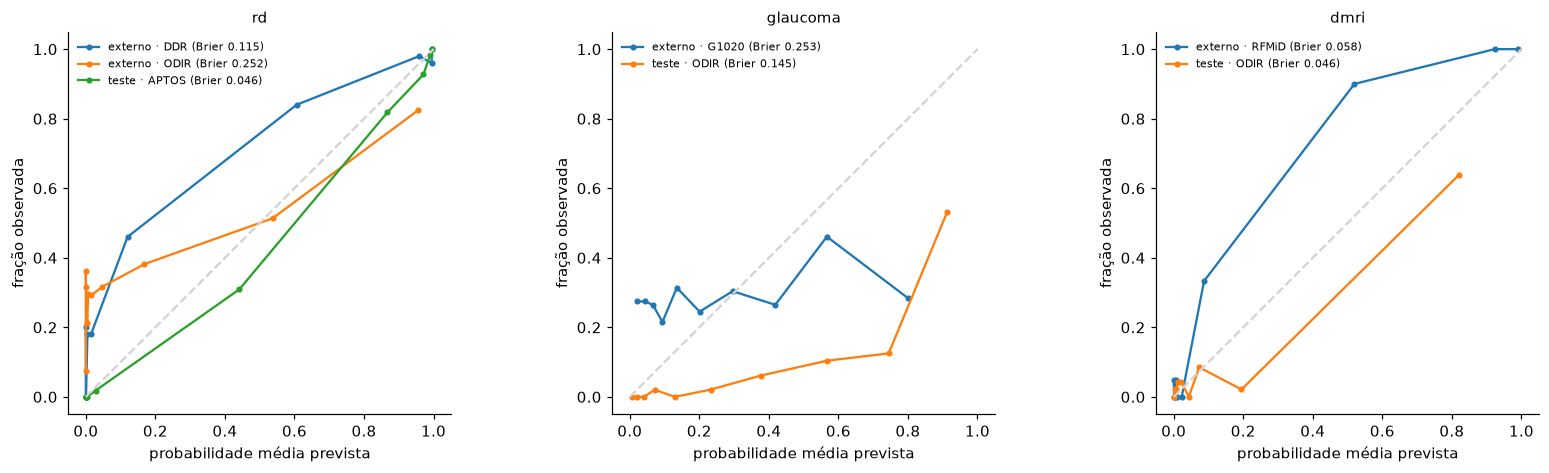

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, tarefa in zip(axs, modelos):
    sub = pred[(pred.tarefa == tarefa) & (pred.particao.isin(["teste", "externo"]))]
    for (particao, fonte), g in sub.groupby(["particao", "fonte"]):
        c = Me.curva_calibracao(g.alvo, g.prob, faixas=10)
        ax.plot(c.p_media, c.observado, "o-", ms=3, label=f"{particao} · {fonte} (Brier {Me.brier(g.alvo, g.prob):.3f})")
    ax.plot([0, 1], [0, 1], color="lightgray", ls="--"); ax.set_xlabel("probabilidade média prevista"); ax.set_ylabel("fração observada")
    ax.set_title(tarefa); ax.legend(frameon=False, fontsize=7); ax.set_aspect("equal")
fig.tight_layout(); V.salvar_figura(fig, "06_calibracao"); plt.show()

Nenhuma curva segue a diagonal. No glaucoma e na DMRI do ODIR (prevalência ≈ 9 %), escores de 0,8–0,9 correspondem a 50–60 % de casos observados:
os **pesos de classe** do treino "fingem" prevalência de 50 % e inflam os escores. No DDR e no RFMiD as curvas ficam **acima** da diagonal (mais doença do
que o escore sugere). O escore ordena bem (AUC), mas não deve ser lido como "chance de doença". No laudo do dispositivo ele aparece como **escore**, ao lado do limiar — nunca como porcentagem.

### O valor preditivo positivo depende da população

Com a sensibilidade e a especificidade medidas no teste, o VPP — "dos encaminhados, quantos têm a condição" — muda drasticamente com a prevalência
(teorema de Bayes). Numa campanha na comunidade a prevalência é baixa; num ambulatório de diabéticos, alta:

In [9]:
prevs = np.array([0.01, 0.02, 0.05, 0.10, 0.20, 0.40])
linhas = {}
for tarefa in modelos:
    t_ = desempenho.loc[(tarefa, next(c for c in desempenho.loc[tarefa].index if c.startswith("teste")))]
    linhas[tarefa] = Me.vpp_por_prevalencia(t_.sensibilidade, t_.especificidade, prevs)
pd.DataFrame(linhas, index=[f"prevalência {p:.0%}" for p in prevs]).round(3).rename_axis("VPP")

,rd,glaucoma,dmri
VPP,,,
prevalência 1%,0.173,0.028,0.049
prevalência 2%,0.297,0.056,0.095
prevalência 5%,0.522,0.133,0.212
prevalência 10%,0.697,0.244,0.363
prevalência 20%,0.838,0.421,0.562
prevalência 40%,0.933,0.659,0.774


## 6. O porteiro: controle de qualidade antes dos modelos

O DDR tem 50 imagens marcadas por especialistas como **sem qualidade para graduação** (grau 5). O que acontece se elas chegam aos modelos? E o controle
de qualidade do Módulo 02 (`retina_pdi.qualidade`) as barra?

In [10]:
from retina_pdi import qualidade as Q
from retina_pdi.pipeline import mascara_fov
ddr = man[man.fonte == "DDR"].copy()
res = []
for i, r in ddr.iterrows():
    rgb = D.carregar_rgb(r.arquivo)
    try:
        q = Q.avaliar_qualidade(rgb, fov=mascara_fov(rgb)); ok = q.adequada
    except ValueError:
        ok = False
    res.append({"id": i, "ilegivel": r.condicao == "ilegivel", "aprovada_qualidade": ok,
                "prob_rd": float(modelos["rd"].prever(cache[[i]])[0])})
qdf = pd.DataFrame(res)
tab = qdf.groupby("ilegivel").agg(imagens=("id", "count"), aprovadas_pelo_QC=("aprovada_qualidade", "mean"),
                                  encaminhadas_RD_sem_QC=("prob_rd", lambda s: (s >= limiares["rd"]).mean()))
tab.index = ["legível (graus 0–4)", "sem qualidade (grau 5)"]; tab.round(3)

,imagens,aprovadas_pelo_QC,encaminhadas_RD_sem_QC
legível (graus 0–4),500,0.632,0.33
sem qualidade (grau 5),50,0.340,0.42


Dois resultados, e os dois importam:

* **Sem o porteiro**, imagens sem qualidade seriam encaminhadas por RD com frequência *maior* que as boas (≈ 42 % × ≈ 33 %): borrão e iluminação ruim
  produzem escores altos sem significado.
* **Com o porteiro do Módulo 02**, 66 % das imagens sem qualidade são barradas — mas **37 % das imagens legíveis também**. Os limiares de qualidade
  foram calibrados no Módulo 02 em outras câmeras e outra resolução; no DDR eles são rígidos demais. Exatamente como o limiar do modelo, os limiares de
  qualidade precisam ser **recalibrados na câmera do projeto** antes do uso.

## 7. Olhando os erros

Os falsos negativos e falsos positivos mais "confiantes" de cada modelo na base externa, com Grad-CAM calculado no modelo Keras correspondente
(o `.tflite` int8 tem as mesmas decisões, a menos do erro de quantização medido no notebook 04):

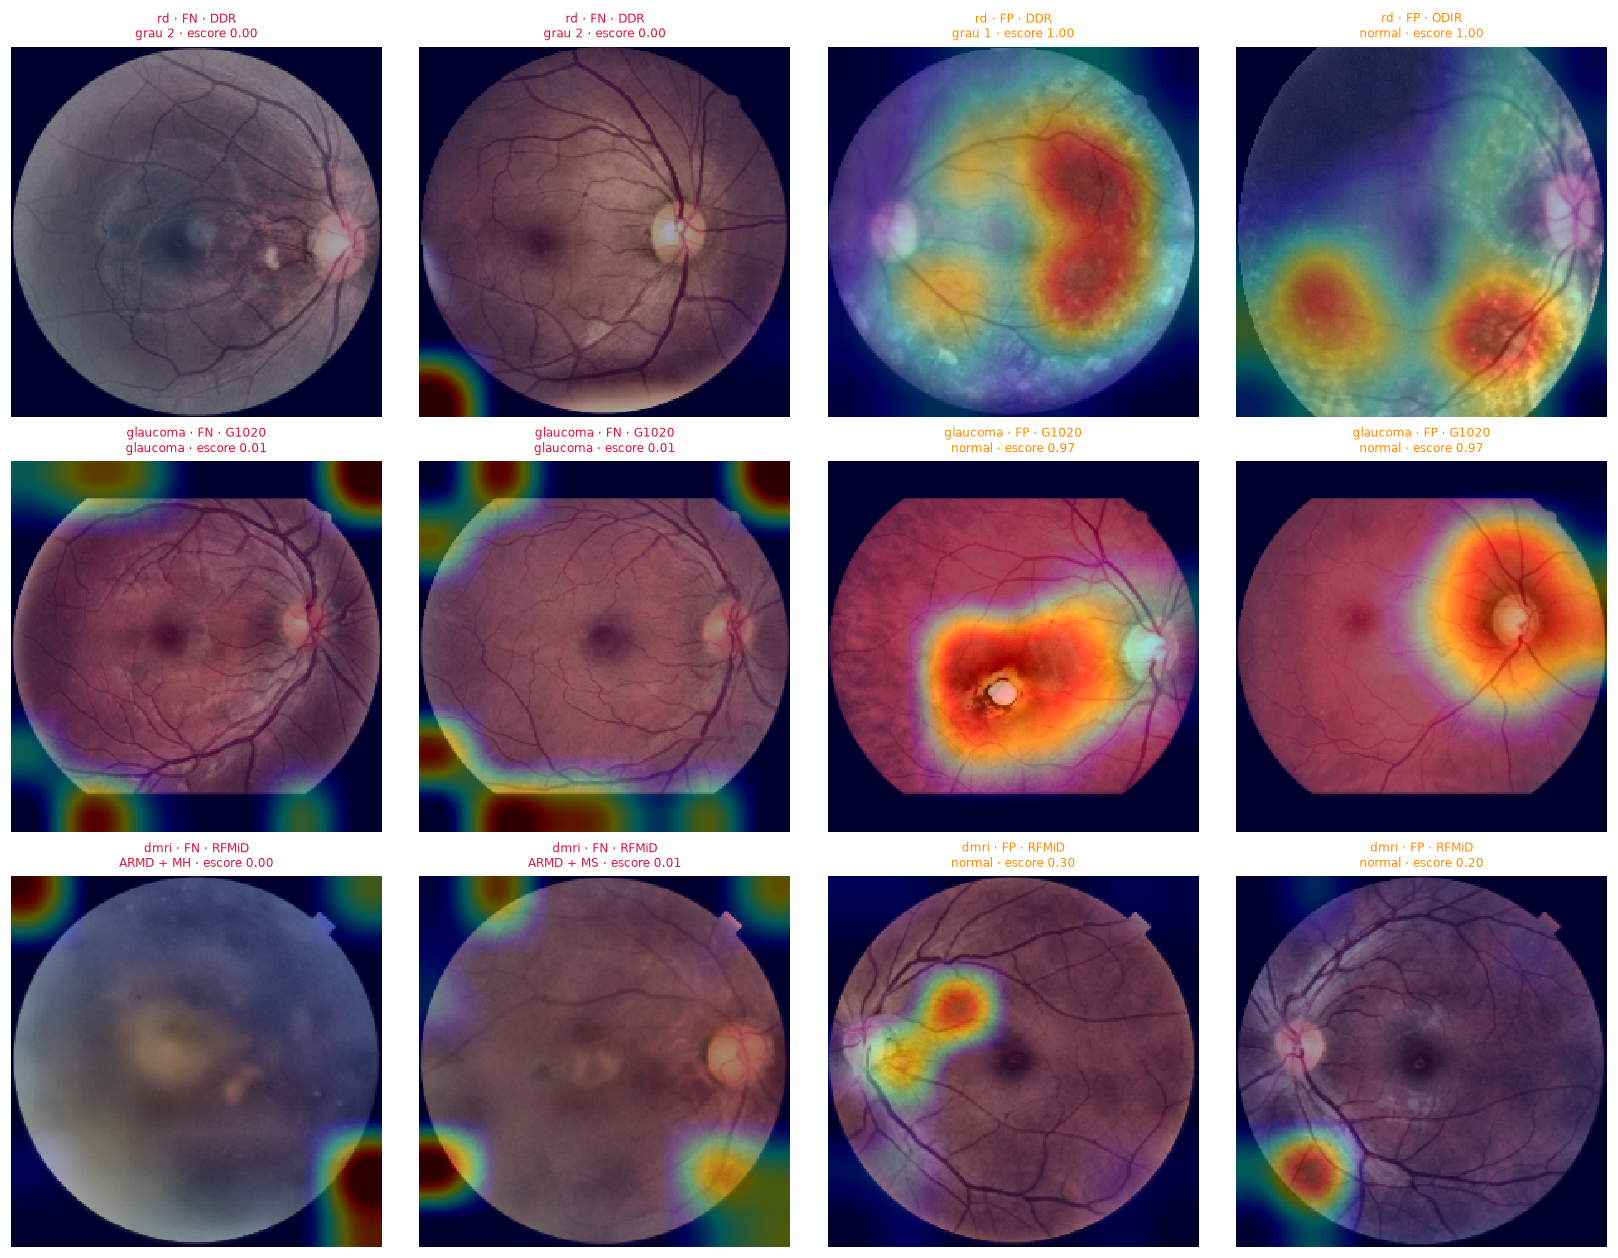

In [11]:
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
from retina_iae import treino as T
from retina_iae.explicacao import gradcam
fig, axs = plt.subplots(3, 4, figsize=(15, 11.5))
for i, tarefa in enumerate(modelos):
    mk = T.carregar(tarefa, cfg["modelos"][tarefa]["arquitetura"])
    ext = pred[(pred.tarefa == tarefa) & (pred.particao == "externo")]
    fn = ext[(ext.alvo == 1)].nsmallest(2, "prob"); fp = ext[(ext.alvo == 0)].nlargest(2, "prob")
    for j, (rot, r) in enumerate([("FN", r) for _, r in fn.iterrows()] + [("FP", r) for _, r in fp.iterrows()]):
        x = cache[r.id]
        axs[i, j].imshow(V.sobrepor_mapa(x, gradcam(mk, x), alpha=0.35)); axs[i, j].axis("off")
        axs[i, j].set_title(f"{tarefa} · {rot} · {r.fonte}\n{man.loc[r.id, 'rotulo_original'][:28]} · escore {r.prob:.2f}", fontsize=8,
                            color="crimson" if rot == "FN" else "darkorange")
fig.tight_layout(); V.salvar_figura(fig, "06_erros_gradcam"); plt.show()

Alguns padrões nesta galeria: os **falsos positivos de RD** são retinas com **outras** lesões claras e pontilhadas (drusas, cicatrizes) — o modelo de RD
nunca viu outras doenças como negativas; nos **falsos negativos de glaucoma**, o Grad-CAM se espalha pela borda e pelo fundo: não há evidência alguma
na imagem; um **falso negativo de DMRI** é uma imagem borrada, que o controle de qualidade deveria ter barrado.

Ao olhar os erros, pergunte para cada um: **o rótulo está certo?** (há erros de rotulagem nas bases públicas); **a imagem tem qualidade?**
(desfoque, reflexo, borda escura); **a lesão é sutil demais para 224 px?**; **o Grad-CAM aponta para a retina ou para um artefato** (borda, reflexo,
etiqueta da câmera)? Erros do último tipo indicam um **atalho** aprendido na fonte de treino — e são os mais perigosos numa câmera nova.

## 8. Cartão do modelo

Os resultados vão para `modelos/CARTAO_DO_MODELO.md` (documentação que acompanha os `.tflite`) e para a seção `metricas` do `config_triagem.json`:

In [12]:
def linha_md(tarefa, conjunto):
    r = desempenho.loc[(tarefa, conjunto)]
    return (f"| {conjunto} | {int(r.n)} ({int(r.positivos)}) | {r.AUC:.3f} ({r.AUC_IC}) | {r.sensibilidade:.2f} ({r.sens_IC}) | "
            f"{r.especificidade:.2f} ({r.esp_IC}) |")

partes = [f"# Cartão do modelo — Retina em Foco · triagem embarcada (v{cfg['versao']})", "",
          f"Gerado por `notebooks/06_Validacao_Experimental.ipynb` em {date.today():%d/%m/%Y}. Projeto Retina em Foco — IFPE Campus Palmares, "
          "Edital FACEPE nº 14/2026.", "",
          "## Uso pretendido",
          "Triagem de retinografias coloridas em um retinógrafo portátil (Raspberry Pi 5), para **apoiar a decisão de encaminhamento** ao oftalmologista. "
          "**Não é diagnóstico.** Protótipo de pesquisa, sem validação clínica prospectiva nem registro na Anvisa; não usar em pacientes.", "",
          "## Entrada e pré-processamento",
          f"Retinografia RGB → `retina_pdi.pipeline.preparar_para_inferencia` (commit `{cfg['preprocessamento']['retina_pdi_commit'][:10]}`): recorte do FOV, "
          f"quadrado, {cfg['preprocessamento']['tamanho']}×{cfg['preprocessamento']['tamanho']}, CLAHE na luminância → tensor uint8. "
          "A captura deve passar no controle de qualidade do Módulo 02.", "",
          "## Modelos", "| Condição | Arquivo | Arquitetura | Limiar | Critério do limiar |", "|---|---|---|---|---|"]
for t, m in cfg["modelos"].items():
    partes.append(f"| {m['nome']} | `{m['arquivo']}` | {m['arquitetura']} (int8) | {m['limiar']:.4f} | {cfg['criterio_limiar']} |")
partes += ["", "## Desempenho (modelo int8, LiteRT)", "n (positivos) · AUC (IC 95 %, bootstrap por paciente) · sensibilidade e especificidade no limiar (IC 95 % de Wilson).", ""]
for t in modelos:
    partes += [f"### {cfg['modelos'][t]['nome']}", "| Conjunto | n (pos.) | AUC | Sensibilidade | Especificidade |", "|---|---|---|---|---|"]
    partes += [linha_md(t, c) for c in desempenho.loc[t].index] + [""]
partes += ["## Dados de treinamento",
           "RD: APTOS 2019 (Índia) · Glaucoma e DMRI: ODIR-5K (China), divisão por paciente. Detalhes, licenças e divisão em `docs/DADOS.md` e `data/particoes.csv`.", "",
           "## Limitações conhecidas",
           "* Rótulos herdados das bases públicas, não revistos por oftalmologista do projeto.",
           "* Desempenho cai em câmeras/populações diferentes das de treino (ver validação externa); **o limiar deve ser recalibrado no retinógrafo do projeto** "
           "com imagens locais rotuladas antes de qualquer uso.",
           "* Escores não são probabilidades calibradas; não exibir como porcentagem.",
           "* Cada modelo foi treinado contra imagens **normais**: a especificidade diante de **outras** doenças não foi medida. Ex.: retinas com RD "
           "podem receber escore alto de DMRI, e drusas ou cicatrizes podem disparar o modelo de RD. Encaminhamentos por uma condição devem ser lidos como "
           "'retina alterada', não como o diagnóstico daquela condição.",
           "* Glaucoma: desempenho muito menor na base externa G1020, cujo rótulo é diagnóstico clínico completo (ver validação externa).",
           "* Amostras pequenas para glaucoma e DMRI: intervalos de confiança largos.",
           "* Nenhuma avaliação por subgrupos (idade, sexo, etnia, comorbidades) com poder estatístico.",
           "* Imagens sem qualidade produzem escores sem significado: o controle de qualidade é obrigatório."]
(D.MODELOS / "CARTAO_DO_MODELO.md").write_text("\n".join(partes) + "\n", encoding="utf-8")

cfg["metricas"] = {t: {c: {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else (int(v) if isinstance(v, (int, np.integer)) else v))
                           for k, v in desempenho.loc[(t, c)][cols].items()} for c in desempenho.loc[t].index} for t in modelos}
(D.MODELOS / "config_triagem.json").write_text(json.dumps(cfg, indent=2, ensure_ascii=False), encoding="utf-8")
print("\n".join(partes[:12])); print("…"); print(f"→ {D.MODELOS.relative_to(D.RAIZ)}/CARTAO_DO_MODELO.md e config_triagem.json atualizados")

# Cartão do modelo — Retina em Foco · triagem embarcada (v1.0)

Gerado por `notebooks/06_Validacao_Experimental.ipynb` em 07/10/2026. Projeto Retina em Foco — IFPE Campus Palmares, Edital FACEPE nº 14/2026.

## Uso pretendido
Triagem de retinografias coloridas em um retinógrafo portátil (Raspberry Pi 5), para **apoiar a decisão de encaminhamento** ao oftalmologista. **Não é diagnóstico.** Protótipo de pesquisa, sem validação clínica prospectiva nem registro na Anvisa; não usar em pacientes.

## Entrada e pré-processamento
Retinografia RGB → `retina_pdi.pipeline.preparar_para_inferencia` (commit `70d02c46d3`): recorte do FOV, quadrado, 224×224, CLAHE na luminância → tensor uint8. A captura deve passar no controle de qualidade do Módulo 02.

## Modelos
| Condição | Arquivo | Arquitetura | Limiar | Critério do limiar |
…
→ modelos/CARTAO_DO_MODELO.md e config_triagem.json atualizados


## Resumo

| Pergunta | Onde respondemos | O que aprendemos |
|---|---|---|
| que limiar? | seção 1 | decisão clínica (sensibilidade-alvo), tomada **só** na validação |
| quão bom? | seção 2 | sempre com IC; teste interno ≠ desempenho real |
| e numa câmera nova? | seções 2–4 | queda esperada; definição do rótulo importa; **recalibrar localmente** |
| o escore é uma probabilidade? | seção 5 | não (descalibrado); o VPP depende da prevalência |
| e as imagens ruins? | seção 6 | o controle de qualidade é parte do modelo |
| por que erra? | seção 7 | rótulo, qualidade, resolução ou atalho — olhar caso a caso |

## Exercícios propostos

1. **Messidor-2.** O espelho `sngsfydy/Messidor2` no Hugging Face (1 744 imagens, graus 0–4, 2,5 GB) é um dos bancos do edital. Acrescente-o como
   fonte externa da tarefa RD (adapte `download_data.py` e `particoes.TAREFAS`) e repita a seção 2.
2. **Subgrupos.** O manifesto do ODIR traz idade e sexo (coluna `observacao`). A sensibilidade do glaucoma muda entre faixas etárias? Com que IC?
3. **Escolha do alvo.** Refaça a exportação do notebook 04 com sensibilidade-alvo de 85 % e de 95 %. Quantos encaminhamentos a mais por 1 000 pessoas
   triadas (prevalência de 5 %) custa cada ponto de sensibilidade?
4. **Calibração.** Ajuste uma calibração de Platt (regressão logística sobre o logit do escore) na validação e compare o Brier no teste e no externo.
   A calibração feita numa fonte serve para a outra?
5. **Concordância.** Rótulos humanos também erram. Pesquise a concordância (kappa) entre oftalmologistas na graduação da RD e discuta: qual é o teto
   realista para a "acurácia" de um modelo avaliado contra um único avaliador?
6. **Protocolo da Fase 2.** Escreva o protocolo de validação local do retinógrafo: quantas imagens, de quem, rotuladas por quem, que métricas e que
   critério de aprovação (use `metricas.ic_proporcao` para dimensionar a amostra que dá um IC de ± 5 pontos na sensibilidade).